In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from astropy.io import fits


from GalVel_Pop import gal_population, UVW

### Reading data

In [2]:
harps_gaia = pd.read_csv('harps_sample.csv')
harps_gaia.head(5)

,Unnamed: 0,source_id,Star,ra,dec,parallax,parallax_error,pmra,pmra_error,pmdec,...,Tp,Tr,TrTp,Tz,U,V,W,jp,jr,jz
0,0,3790755044736796544,BD-012505,169.304406,-1.981918,30.138378,0.023513,-568.299830,0.017789,-14.309893,...,0.215211,0.158178,2.309044,0.090947,-76.948615,-35.217054,-29.235845,1602.694743,67.192390,3.707134
1,1,4706630501049679744,HD55,1.322329,-67.835081,61.006400,0.019343,-116.617908,0.019904,-560.587881,...,0.196349,0.143201,2.291224,0.071753,35.732556,-48.103695,-0.865637,1494.455057,59.348105,0.279256
2,2,5480937375656689408,HD42505,91.683263,-62.681825,35.384393,0.013205,63.838962,0.018247,176.640253,...,0.211094,0.156448,2.328325,0.077354,-22.182569,-26.273855,-2.628323,1673.582105,7.030067,0.151234
3,3,5938742337829520256,HD154387,256.880988,-48.248481,36.527404,0.018006,26.332181,0.021347,-35.901501,...,0.251845,0.188608,2.352753,0.094417,-20.629661,5.760077,-3.813733,1927.745207,11.969423,0.093923
4,4,2460132463713337472,BD-130321,26.931812,-12.769909,27.501795,0.018170,253.272569,0.016348,167.272805,...,0.244813,0.182701,2.344530,0.098960,-52.059615,-3.990877,8.942840,1857.153670,27.131766,1.906507


In [3]:
gr8_full = pd.read_csv('gr8stars_paper1_results_revision7.csv')
gr8_full.head(5)

,ra_j2000,dec_j2000,primary_name,gaiadr3_source_id,hip,hd,tic,parallax,pmra,pmdec,...,chisq_SED,npts_SED,radius_SED,radius_SED_ubound,radius_SED_lbound,Teff_SED,Teff_SED_ubound,Teff_SED_lbound,filtered_otypes_flag,good_flag
0,41.560870,5.592591,HD17250,Gaia DR3 6478258087046528,12925.0,17250,318841562.0,17.5306,74.943,-44.521,...,3.794560,8.0,1.240766,1.264745,1.212816,6090.0,6161.81592,6030.19824,False,False
1,45.961727,6.133301,HD19019,Gaia DR3 6963761190199424,14258.0,19019,365294034.0,31.9791,232.147,49.838,...,0.180816,5.0,1.049715,1.068969,1.023852,6110.0,6182.12402,6054.90674,True,False
2,45.150406,5.986063,HD18702,Gaia DR3 6989290475763456,14023.0,18702,347572104.0,30.3219,698.233,-158.181,...,0.448097,5.0,0.900855,0.926940,0.886053,5310.0,5345.65137,5247.24707,True,True
3,45.011715,7.749755,HD18632,Gaia DR3 8479094371605632,13976.0,18632,387609654.0,42.0781,328.026,21.181,...,2.764974,5.0,0.801557,0.826541,0.789833,5040.0,5066.29492,4975.70654,False,False
4,52.054314,7.302224,HD21496,Gaia DR3 9994255754844928,16158.0,21496,399965184.0,11.2177,-14.804,-82.405,...,2.947178,8.0,1.866663,1.902498,1.836472,6050.0,6107.24121,5986.30176,False,True


In [4]:
print (gr8_full[gr8_full['Teff(K)'].between(5000, 6500)].shape)
gr8_full = gr8_full[gr8_full['Teff(K)'].between(5000, 6500)]

(1615, 75)


#### UW nad UVW velocities

In [5]:
# Define a function to apply gal_population to each row
def calculate_UVW(row):
    UVW_values =  UVW(row['ra_j2000'], row['dec_j2000'], row['pmra'], row['pmdec'], row['radial_velocity'], row['parallax'])
    return pd.Series(UVW_values, index=['U_lsr', 'V_lsr', 'W_lsr'])

gr8_full[['U_lsr', 'V_lsr', 'W_lsr']] = gr8_full.apply(lambda row: calculate_UVW(row), axis=1)


Please check the value of vrad
Please check the value of vrad
Please check the value of vrad
Please check the value of vrad
Please check the value of vrad
Please check the value of vrad
Please check the value of vrad
Please check the value of vrad
Please check the value of vrad
Please check the value of vrad
Please check the value of vrad
Please check the value of vrad
Please check the value of vrad
Please check the value of vrad
Please check the value of vrad
Please check the value of vrad
Please check the value of vrad
Please check the value of vrad
Please check the value of vrad
Please check the value of vrad
Please check the value of vrad
Please check the value of vrad
Please check the value of vrad
Please check the value of vrad
Please check the value of vrad
Please check the value of vrad
Please check the value of vrad
Please check the value of vrad
Please check the value of vrad
Please check the value of vrad
Please check the value of vrad
Please check the value of vrad
Please c

In [6]:
gr8_columns = ['ra_j2000', 'dec_j2000', 'gaiadr3_source_id', 
               'parallax', 'pmra', 'pmdec', 'gmag',
       'radial_velocity',  'Teff(K)', 'Teff_err(K)',
       'logg', 'logg_err', 'Fe/H', 'Fe/H_err', 
       'U_lsr', 'V_lsr', 'W_lsr',]

gr8_full = gr8_full[gr8_columns]

In [7]:
# Step 1: Remove 'Gaia DR3 ' prefix and convert to integer
gr8_full = gr8_full.copy()
gr8_full['source_id'] = gr8_full['gaiadr3_source_id'].str.replace('Gaia DR3 ', '', regex=False).astype('int64')

# Step 2: Make sure harps_gaia['source_id'] is also int64 (just in case)
harps_gaia['source_id'] = harps_gaia['source_id'].astype('int64')

# Step 3: Merge on 'source_id' with suffixes
merged_df = pd.merge(
    gr8_full,
    harps_gaia,
    on='source_id',
    how='inner',  # or 'left', 'right', 'outer' depending on what you want
    suffixes=('_gr8', '_harps')
)

gr8_not_in_harps = gr8_full[~gr8_full['source_id'].isin(harps_gaia['source_id'])]


In [8]:
merged_df['delta_fe'] = merged_df['Fe/H'] - merged_df['fe_h']

In [9]:
merged_df['delta_fe'].describe()

count    114.000000
mean       0.003860
std        0.069135
min       -0.160000
25%       -0.040000
50%        0.000000
75%        0.050000
max        0.220000
Name: delta_fe, dtype: float64

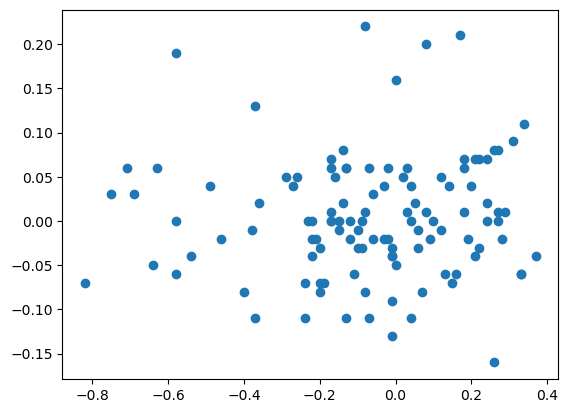

In [10]:
plt.scatter(merged_df['fe_h'], merged_df['delta_fe'])

In [11]:
# Some targets do not have RV or distances. Removed
gr8_not_in_harps.dropna(inplace=True)
print (gr8_not_in_harps.shape)

(1436, 18)


/tmp/ipykernel_200324/3770648642.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  gr8_not_in_harps.dropna(inplace=True)


In [12]:
# Define a function to apply gal_population to each row
def calculate_probabilities(row):
    probs =  gal_population(row['U_lsr'], row['V_lsr'], row['W_lsr'], char_vel='Mean')
    return probs[0]

# Apply the function to each row using apply with axis=1
gr8_not_in_harps['P_gal'] = gr8_not_in_harps.apply(calculate_probabilities, axis=1)

/tmp/ipykernel_200324/3317594757.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  gr8_not_in_harps['P_gal'] = gr8_not_in_harps.apply(calculate_probabilities, axis=1)


In [13]:
gr8_not_in_harps = gr8_not_in_harps[gr8_not_in_harps['Fe/H'] > -1]

In [14]:
gr8_not_in_harps.columns

Index(['ra_j2000', 'dec_j2000', 'gaiadr3_source_id', 'parallax', 'pmra',
       'pmdec', 'gmag', 'radial_velocity', 'Teff(K)', 'Teff_err(K)', 'logg',
       'logg_err', 'Fe/H', 'Fe/H_err', 'U_lsr', 'V_lsr', 'W_lsr', 'source_id',
       'P_gal'],
      dtype='object')

In [15]:
# Mapping from gr8 column names to harps column names

gr8_rename_map = {
    'ra_j2000': 'ra',
    'dec_j2000': 'dec',
    'parallax': 'parallax',
    'pmra': 'pmra',
    'pmdec': 'pmdec',
    'gmag': 'phot_g_mean_mag',
    'radial_velocity': 'radial_velocity',
    'Teff(K)': 'Teff',
    'Teff_err(K)': 'e_Teff',
    'logg': 'logg',
    'logg_err': 'e_logg',
    'Fe/H': 'fe_h',
    'Fe/H_err': 'e_fe_h',
    'P_gal': 'P_gal',
    'U_lsr': 'U_lsr',
    'V_lsr': 'V_lsr',
    'W_lsr': 'W_lsr',
    'source_id': 'source_id'
}

gr8_renamed = gr8_not_in_harps.rename(columns=gr8_rename_map).copy()
gr8_renamed.to_csv('gr8_not_in_harps_sample_tmp.csv', index=False)
gr8_renamed.head(2)

,ra,dec,gaiadr3_source_id,parallax,pmra,pmdec,phot_g_mean_mag,radial_velocity,Teff,e_Teff,logg,e_logg,fe_h,e_fe_h,U_lsr,V_lsr,W_lsr,source_id,P_gal
0,41.560870,5.592591,Gaia DR3 6478258087046528,17.5306,74.943,-44.521,7.754348,6.05,6012.0,135.0,4.16,0.21,-0.22,0.06,0.359071,-9.121123,5.100817,6478258087046528,99.1
1,45.961727,6.133301,Gaia DR3 6963761190199424,31.9791,232.147,49.838,6.792566,24.68,6097.0,100.0,4.37,0.10,-0.04,0.04,29.084304,-2.605049,10.822053,6963761190199424,98.8
